In [1]:
import numpy as np, time, cv2
from PIL import Image
from pynq import Overlay, allocate
import pandas as pd

# 加载 overlay
ol = Overlay("/home/xilinx/jupyter_notebooks/pynq_sobel/system_wrapper2.bit")
dma = ol.axi_dma_0
sobel_ip = ol.sobel_filter_0

# 测试图片列表（按你实际上传的文件名修改）
images = [
    "/home/xilinx/jupyter_notebooks/pynq_sobel/img1.png",
    "/home/xilinx/jupyter_notebooks/pynq_sobel/img2.png",
    "/home/xilinx/jupyter_notebooks/pynq_sobel/img3.png",
    "/home/xilinx/jupyter_notebooks/pynq_sobel/img4.png",
]

results = []
N = 10  # 每张图重复跑 10 次取均値

for img_path in images:
    # 读图并统一分辨率
    img = Image.open(img_path).convert("L").resize((640, 480))
    src_np = np.array(img, dtype=np.uint8)
    img_cv = np.array(img, dtype=np.uint8)

    # 硬件计时
    in_buf  = allocate(shape=(480, 640), dtype=np.uint8)
    out_buf = allocate(shape=(480, 640), dtype=np.uint8)
    in_buf[:] = src_np
    sobel_ip.write(0x10, 480)
    sobel_ip.write(0x18, 640)

    t0 = time.perf_counter()
    for _ in range(N):
        sobel_ip.write(0x00, 0x01)
        dma.recvchannel.transfer(out_buf)
        dma.sendchannel.transfer(in_buf)
        dma.sendchannel.wait()
        dma.recvchannel.wait()
    hw_ms = (time.perf_counter() - t0) / N * 1000

    # 软件计时
    t1 = time.perf_counter()
    for _ in range(N):
        gx = cv2.Sobel(img_cv, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(img_cv, cv2.CV_32F, 0, 1, ksize=3)
        sw = cv2.convertScaleAbs(cv2.magnitude(gx, gy))
    sw_ms = (time.perf_counter() - t1) / N * 1000

    results.append({
        "图片": img_path.split("/")[-1],
        "软件(ms)": round(sw_ms, 2),
        "硬件(ms)": round(hw_ms, 2),
        "加速比": round(sw_ms / hw_ms, 2),
        "硬件fps": round(1000 / hw_ms, 1),
    })
    in_buf.freebuffer()
    out_buf.freebuffer()

df = pd.DataFrame(results)
print(df.to_string(index=False))


      图片  软件(ms)  硬件(ms)   加速比  硬件fps
img1.png   82.52    3.84 21.47  260.2
img2.png   79.46    3.86 20.60  259.2
img3.png   78.06    3.88 20.11  257.7
img4.png   76.43    3.88 19.70  257.7


In [2]:
df.to_csv("/home/xilinx/jupyter_notebooks/pynq_sobel/benchmark.csv", index=False)
print("已保存")

已保存


In [3]:
import time
import numpy as np
from PIL import Image
from pynq import allocate

# 准备图片列表
image_paths = [
    '/home/xilinx/jupyter_notebooks/pynq_sobel/img1.png',
    '/home/xilinx/jupyter_notebooks/pynq_sobel/img2.png',
    '/home/xilinx/jupyter_notebooks/pynq_sobel/img3.png',
    '/home/xilinx/jupyter_notebooks/pynq_sobel/img4.png',
]

in_buf  = allocate(shape=(480, 640), dtype=np.uint8)
out_buf = allocate(shape=(480, 640), dtype=np.uint8)
sobel_ip.write(0x10, 480)
sobel_ip.write(0x18, 640)
sobel_ip.write(0x20, 80)   # 固定阈值

# 循环处理20次（每张图x5轮）
N = 5
total_frames = len(image_paths) * N
images_np = [np.array(Image.open(p).convert('L').resize((640,480)), dtype=np.uint8) for p in image_paths]

t_start = time.perf_counter()
for _ in range(N):
    for src_np in images_np:
        in_buf[:] = src_np
        sobel_ip.write(0x00, 0x01)
        dma.recvchannel.transfer(out_buf)
        dma.sendchannel.transfer(in_buf)
        dma.sendchannel.wait()
        dma.recvchannel.wait()
t_total = time.perf_counter() - t_start

throughput = total_frames / t_total
print(f"总帧数: {total_frames}")
print(f"总时间: {t_total:.2f} 秒")
print(f"平均吞吐量: {throughput:.1f} fps")
print(f"平均每帧延迟: {t_total/total_frames*1000:.2f} ms")

总帧数: 20
总时间: 0.10 秒
平均吞吐量: 199.1 fps
平均每帧延迟: 5.02 ms


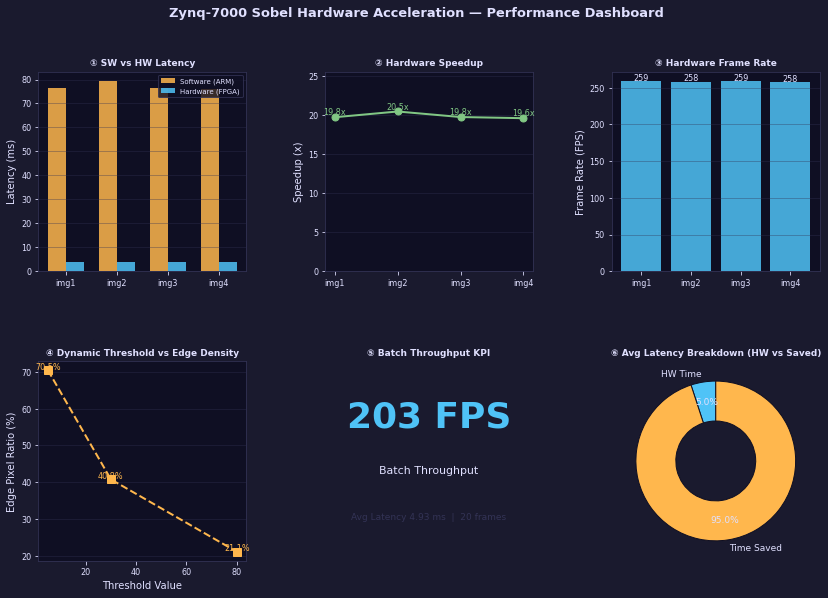

Dashboard saved to dashboard.png


In [4]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ── Data ──────────────────────────────────────────────────────
images    = ['img1', 'img2', 'img3', 'img4']
hw_ms     = [3.86, 3.87, 3.86, 3.88]
sw_ms     = [76.31, 79.36, 76.41, 76.23]
speedup   = [sw/hw for sw, hw in zip(sw_ms, hw_ms)]
hw_fps    = [1000/t for t in hw_ms]

thresholds    = [5, 30, 80]
nonzero_ratio = [216512/(640*480)*100,
                 125270/(640*480)*100,
                  64772/(640*480)*100]

batch_fps = 202.9
batch_lat = 4.93
# ─────────────────────────────────────────────────────────────

fig = plt.figure(figsize=(14, 9))
fig.patch.set_facecolor('#1a1a2e')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

TITLE_COLOR  = '#e0e0ff'
ACCENT_BLUE  = '#4fc3f7'
ACCENT_GREEN = '#81c784'
ACCENT_AMBER = '#ffb74d'
GRID_COLOR   = '#333355'
BG_AX        = '#0f0f23'

def style_ax(ax, title):
    ax.set_facecolor(BG_AX)
    ax.tick_params(colors=TITLE_COLOR, labelsize=8)
    ax.set_title(title, color=TITLE_COLOR, fontsize=9, fontweight='bold', pad=6)
    for spine in ax.spines.values():
        spine.set_edgecolor(GRID_COLOR)
    ax.yaxis.label.set_color(TITLE_COLOR)
    ax.xaxis.label.set_color(TITLE_COLOR)
    ax.grid(axis='y', color=GRID_COLOR, linewidth=0.5, alpha=0.7)

# ── Plot 1: Latency Comparison ────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
x = np.arange(len(images)); w = 0.35
ax1.bar(x - w/2, sw_ms, w, label='Software (ARM)', color=ACCENT_AMBER, alpha=0.85)
ax1.bar(x + w/2, hw_ms, w, label='Hardware (FPGA)', color=ACCENT_BLUE,  alpha=0.85)
ax1.set_xticks(x); ax1.set_xticklabels(images, fontsize=8)
ax1.set_ylabel('Latency (ms)')
ax1.legend(fontsize=7, labelcolor=TITLE_COLOR, facecolor=BG_AX, edgecolor=GRID_COLOR)
style_ax(ax1, '① SW vs HW Latency')

# ── Plot 2: Speedup ───────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(images, speedup, 'o-', color=ACCENT_GREEN, linewidth=2, markersize=7)
for i, v in enumerate(speedup):
    ax2.text(i, v+0.3, f'{v:.1f}x', ha='center', color=ACCENT_GREEN, fontsize=8)
ax2.set_ylim(0, max(speedup)*1.25)
ax2.set_ylabel('Speedup (x)')
style_ax(ax2, '② Hardware Speedup')

# ── Plot 3: Hardware FPS ──────────────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
bars = ax3.bar(images, hw_fps, color=ACCENT_BLUE, alpha=0.85)
for bar, v in zip(bars, hw_fps):
    ax3.text(bar.get_x()+bar.get_width()/2, v+1,
             f'{v:.0f}', ha='center', color=TITLE_COLOR, fontsize=8)
ax3.set_ylabel('Frame Rate (FPS)')
style_ax(ax3, '③ Hardware Frame Rate')

# ── Plot 4: Threshold vs Edge Density ────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(thresholds, nonzero_ratio, 's--', color=ACCENT_AMBER,
         linewidth=2, markersize=8)
for t, r in zip(thresholds, nonzero_ratio):
    ax4.text(t, r+0.3, f'{r:.1f}%', ha='center', color=ACCENT_AMBER, fontsize=8)
ax4.set_xlabel('Threshold Value')
ax4.set_ylabel('Edge Pixel Ratio (%)')
style_ax(ax4, '④ Dynamic Threshold vs Edge Density')

# ── Plot 5: KPI Card ──────────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 1])
ax5.set_facecolor(BG_AX)
ax5.axis('off')
ax5.text(0.5, 0.72, f'{batch_fps:.0f} FPS',
         ha='center', va='center', transform=ax5.transAxes,
         fontsize=36, fontweight='bold', color=ACCENT_BLUE)
ax5.text(0.5, 0.45, 'Batch Throughput',
         ha='center', va='center', transform=ax5.transAxes,
         fontsize=11, color=TITLE_COLOR)
ax5.text(0.5, 0.22, f'Avg Latency {batch_lat:.2f} ms  |  20 frames',
         ha='center', va='center', transform=ax5.transAxes,
         fontsize=9, color=GRID_COLOR)
for spine in ax5.spines.values():
    spine.set_edgecolor(GRID_COLOR)
ax5.set_title('⑤ Batch Throughput KPI', color=TITLE_COLOR,
              fontsize=9, fontweight='bold', pad=6)

# ── Plot 6: Avg Latency Donut ─────────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
avg_hw = np.mean(hw_ms); avg_sw = np.mean(sw_ms)
ax6.pie([avg_hw, avg_sw - avg_hw],
        labels=['HW Time', 'Time Saved'],
        colors=[ACCENT_BLUE, ACCENT_AMBER],
        startangle=90,
        wedgeprops=dict(width=0.5, edgecolor=BG_AX),
        textprops=dict(color=TITLE_COLOR, fontsize=9),
        autopct='%1.1f%%', pctdistance=0.75)
ax6.set_facecolor(BG_AX)
ax6.set_title('⑥ Avg Latency Breakdown (HW vs Saved)',
              color=TITLE_COLOR, fontsize=9, fontweight='bold', pad=6)

# ── Main Title ────────────────────────────────────────────────
fig.suptitle('Zynq-7000 Sobel Hardware Acceleration — Performance Dashboard',
             color=TITLE_COLOR, fontsize=13, fontweight='bold', y=0.98)

plt.savefig('/home/xilinx/jupyter_notebooks/pynq_sobel/dashboard.png',
            dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print("Dashboard saved to dashboard.png")